# 04 · What is a March member worth?

Keeping a member is worth the subscription they would go on paying. From the payment history
before 1 March 2017, every member's subscription is split into **spells** (continuous paid
periods; a gap of more than 30 days starts a new one). Kaplan–Meier curves by plan type and
auto-renew give the chance a spell is still running after each month, counting spells that are
still running as censored. A member's lifetime value, as fixed in the plan, is their expected
remaining paid months over **24 months**, times their monthly payment, times an assumed **30%
gross margin**. Sensitivity: 12 and 36 months, 20% and 40% margin.

In [1]:
import sys
from pathlib import Path


def _root() -> Path:
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "src" / "data" / "kkbox.py").exists():
            return p
    raise FileNotFoundError("run from inside the project folder")


ROOT = _root()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import records
from src.churn import ltv
from src.data import kkbox

con, SOURCE = kkbox.connect()
CUT = kkbox.CUTOFF["mar"]
HORIZON, MARGIN = 24, 0.30
sp = ltv.spells(con, CUT)
print(f"source: {SOURCE}; {len(sp):,} spells from {sp['msno'].nunique():,} members; "
      f"{sp['censored'].mean():.0%} still running at the cutoff")

source: real; 2,953,528 spells from 2,375,164 members; 39% still running at the cutoff


## 1. Survival by plan type and auto-renew

In [2]:
groups, curves = {}, {}
observed = int(np.floor(sp["months"].max()))
for (plan, ar), g in sp.groupby(["plan", "auto_renew"]):
    if len(g) < 1000:
        continue
    key = f"{plan}, auto-renew {'on' if ar == 1 else 'off'}"
    s = ltv.kaplan_meier(g["months"].to_numpy(), g["censored"].to_numpy(), horizon=observed)
    curves[key] = ltv.extend(s, observed=min(observed, 24), horizon=36 + observed)
    groups[key] = {"spells": int(len(g)), "survival_6": float(s[6]), "survival_12": float(s[12]),
                   "survival_24": float(s[min(24, observed)])}
pd.DataFrame(groups).T.round(3)

,spells,survival_6,survival_12,survival_24
"longer, auto-renew off",261282.0,0.953,0.820,0.616
"monthly, auto-renew off",1019266.0,0.183,0.119,0.042
"monthly, auto-renew on",1672980.0,0.684,0.606,0.436


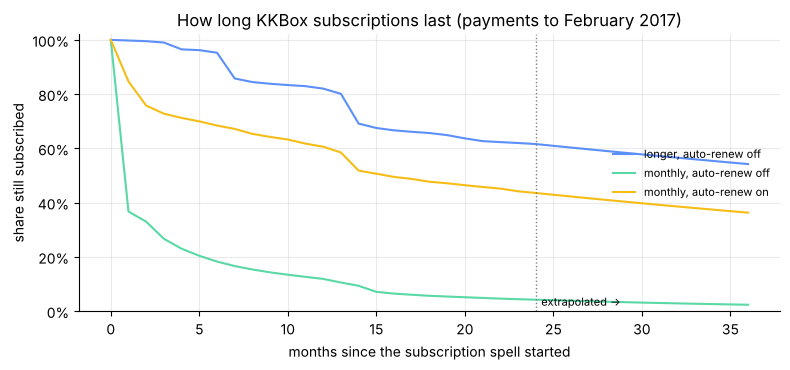

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.8))
for (k, s), col in zip(curves.items(), ["#5B8FF9", "#5AD8A6", "#F6BD16", "#F6735B"]):
    ax.plot(np.arange(len(s))[:37], s[:37], color=col, label=k)
ax.axvline(min(observed, 24), color="#7F7F7F", ls=":", lw=1)
ax.annotate("extrapolated →", (min(observed, 24), 0.02), xytext=(4, 0), textcoords="offset points", fontsize=8)
ax.set(xlabel="months since the subscription spell started", ylabel="share still subscribed",
       title="How long KKBox subscriptions last (payments to February 2017)", ylim=(0, 1.02))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.legend(frameon=False, fontsize=8, loc="center right")
ax.grid(alpha=0.25)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
records.save_figure(fig, "04_kkbox_lifetime_value.png", SOURCE)

## 2. Each March member's value

In [4]:
mar_ids = kkbox.labels(con, "mar")[["msno"]]       # members only; labels are not used here
cur = (sp[sp["censored"]].sort_values("start").groupby("msno").tail(1)
       .assign(age=lambda d: (pd.Timestamp(str(CUT)) - d["start"]).dt.days / ltv.MONTH))
cur = mar_ids.merge(cur, on="msno", how="left")
cur["group"] = cur["plan"].fillna("monthly") + ", auto-renew " + np.where(cur["auto_renew"] == 1, "on", "off")
cur["group"] = cur["group"].where(cur["group"].isin(curves), "monthly, auto-renew off")
cur["age"] = cur["age"].fillna(0).clip(lower=0)
cur["monthly_paid"] = cur["monthly_paid"].fillna(0).clip(lower=0, upper=1000)
for h in (12, 24, 36):
    cur[f"months_{h}"] = 0.0
    for g, idx in cur.groupby("group").groups.items():
        cur.loc[idx, f"months_{h}"] = ltv.remaining_months(curves[g], cur.loc[idx, "age"].to_numpy(), h)
for h, mg in ((24, 0.30), (12, 0.30), (36, 0.30), (24, 0.20), (24, 0.40)):
    cur[f"ltv_{h}_{int(mg * 100)}"] = cur[f"months_{h}"] * cur["monthly_paid"] * mg
cur["ltv"] = cur["ltv_24_30"]
summary = cur[["monthly_paid", "months_24", "ltv"]].describe(percentiles=[0.1, 0.5, 0.9]).T
cur[["msno", "group", "age", "monthly_paid", "months_24", "ltv"] + [c for c in cur if c.startswith("ltv_")]].to_parquet(
    kkbox.features_dir(SOURCE) / "mar_ltv.parquet", index=False)
summary.round(1)

,count,mean,std,min,10%,50%,90%,max
monthly_paid,970960.0,130.4,31.2,0.0,100.3,151.0,151.0,212.8
months_24,970960.0,17.6,3.4,3.2,14.0,17.7,20.0,21.4
ltv,970960.0,686.6,199.9,0.0,484.2,625.1,904.4,1274.6


In [5]:
record = {"spells": int(len(sp)), "members": int(sp["msno"].nunique()), "share_censored": float(sp["censored"].mean()),
          "observed_months": observed, "groups": groups, "horizon": HORIZON, "margin": MARGIN,
          "mar_members": int(len(cur)), "median_monthly_paid": float(cur["monthly_paid"].median()),
          "ltv_mean": float(cur["ltv"].mean()), "ltv_median": float(cur["ltv"].median()),
          "ltv_mean_sensitivity": {c: float(cur[c].mean()) for c in cur if c.startswith("ltv_")},
          "group_shares": cur["group"].value_counts(normalize=True).to_dict()}
print("wrote", records.write("04_kkbox_lifetime_value", record, SOURCE).name)
print(f"A March member is worth NT${cur['ltv'].mean():,.0f} on average (median NT${cur['ltv'].median():,.0f}) in margin "
      f"over 24 months: {cur['months_24'].mean():.1f} expected paid months at a median NT${cur['monthly_paid'].median():.0f} a month.")

wrote 04_kkbox_lifetime_value.json
A March member is worth NT$687 on average (median NT$625) in margin over 24 months: 17.6 expected paid months at a median NT$151 a month.
